# TriggerNet Level 2 — Notebook 06: CERN `PQuantML` Compression Sweep & Hero Pareto Plot

## What Makes This Notebook Stand Out to CERN Next Generation Triggers (NGT)
In Notebook 03, we wrote our own fixed-point STE quantizer from scratch to understand the math.
Now in **Level 2**, we plug our **Deep Sets** particle-set classifier directly into **CERN's own Next Generation Triggers compression library: [`PQuantML`](https://github.com/cern-nextgen/PQuantML)** (`arXiv:2603.26595`)!

### How `PQuantML` Compresses Deep Sets Under the Hood
1. `pquant.add_compression_layers(model, config, input_shape)` automatically inspects our PyTorch `DeepSetsJetTagger` and swaps every `nn.Linear` → **`PQDense`** and every `nn.ReLU` → **`PQActivation`**.
2. **Quantization (`4, 6, 8, 12, 16` bits):** Each `PQDense` layer inserts hardware-accurate fixed-point quantizers (`SAT` saturation + `RND` rounding) on both weights/biases and data lanes (`ap_fixed<W, I>`).
3. **Progressive Differentiable Pruning (`pdp_config`, `0% → 90%` sparsity):** Unlike crude one-shot pruning, CERN's PDP algorithm computes a **global layer-wise sparsity budget** (`_pdp_setup`) and gradually drives weak weights to zero during `pquant.train_model(...)` before locking masks during fine-tuning.
4. **Official CERN Hardware Cost (`pquant.get_ebops(model)`):** Computes exact **Effective Bit-Operations (eBOPs)** across **all `N` constituent particles** in `φ(x_i)` plus `ρ(pooled)`, counting ONLY surviving non-zero weights above the quantization step size!

### The Sweep Grid
- **Bit widths:** `16, 12, 8, 6, 4` bits
- **Pruning targets:** `0%, 50%, 75%, 90%`
- **Deliverable:** One flagship **Hero Pareto Frontier Figure** (`figures/06_level2_hero_pareto.png`) plotting **Macro ROC AUC** and **Trigger Background Rejection (`1/FPR @ 50%`)** against **Official `PQuantML` eBOPs**!

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

from pathlib import Path
import json
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pquant
from src.deepsets import DeepSetsJetTagger
from src.level2_data import (
    CLASS_NAMES,
    PUBLISHED_ODAGIU_2024,
    load_h5_folder,
    standardize_constituents,
    generate_synthetic_constituent_jets,
)
from src.pquant_sweep import run_pquant_compression_experiment

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = PROJECT_ROOT / "checkpoints"
FIG_DIR = PROJECT_ROOT / "figures"
RES_DIR = PROJECT_ROOT / "results"
ZENODO_DIR = PROJECT_ROOT / "data" / "zenodo_3602260"

ckpt = torch.load(CKPT_DIR / "level2_deepsets_fp32.pt", map_location=device, weights_only=False)
DATA_MODE = ckpt["data_mode"]
N_CONSTITUENTS = ckpt["n_constituents"]

base_model = DeepSetsJetTagger(in_features=3, hidden_dim=ckpt["hidden_dim"], num_classes=5).to(device)
base_model.load_state_dict(ckpt["state_dict"])
base_model.eval()

print(f"PQuantML backend : {pquant.backend}")
print(f"Data Mode        : {DATA_MODE} (N={N_CONSTITUENTS} particles/jet)")
print(f"FP32 Baseline    : Acc={ckpt['metrics']['accuracy']*100:.2f}%, Macro AUC={ckpt['metrics']['macro_auc']:.4f}")

if DATA_MODE == "REAL_ZENODO_3602260":
    X_trval_raw, y_trval, _ = load_h5_folder(ZENODO_DIR / "train", n_constituents=N_CONSTITUENTS)
    X_test_raw, y_test, _ = load_h5_folder(ZENODO_DIR / "val", n_constituents=N_CONSTITUENTS)
    X_train_raw, X_val_raw, y_train, y_val = train_test_split(
        X_trval_raw, y_trval, test_size=0.20, random_state=42, stratify=y_trval
    )
else:
    X_all, y_all, _ = generate_synthetic_constituent_jets(n_jets=15_000, n_constituents=N_CONSTITUENTS)
    X_train_raw, X_tmp, y_train, y_tmp = train_test_split(X_all, y_all, test_size=0.40, random_state=42, stratify=y_all)
    X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)

X_train, X_val, X_test, _, _ = standardize_constituents(X_train_raw, X_val_raw, X_test_raw)
X_tr_t, y_tr_t = torch.from_numpy(X_train).to(device), torch.from_numpy(y_train).to(device)
X_va_t, y_va_t = torch.from_numpy(X_val).to(device), torch.from_numpy(y_val).to(device)
X_te_t = torch.from_numpy(X_test).to(device)

PQuantML backend : torch
Data Mode        : LOCAL_SYNTHETIC_DRY_RUN (N=32 particles/jet)
FP32 Baseline    : Acc=58.73%, Macro AUC=0.8979


## 1. Run Full `PQuantML` Bit-Width × Pruning Sweep (`4` to `16` bits × `0%` to `90%` sparsity)
Watch each row print CERN `PQuantML`'s live `actual_sparsity`, official `eBOPs`, Test Accuracy, Macro AUC, and Background Rejection (`1/FPR @ 50%`)!

In [2]:
BIT_WIDTHS = [16, 12, 8, 6, 4]
SPARSITIES = [0.0, 0.50, 0.75, 0.90]

PRUNE_EP = 10 if DATA_MODE == "REAL_ZENODO_3602260" else 5
FT_EP = 5 if DATA_MODE == "REAL_ZENODO_3602260" else 3
BS = 2048 if device.type == "cuda" else 512

# Estimate FP32 baseline BOPs on the exact same N_CONSTITUENTS formula for reference
# phi MACs: N * (3*32 + 32*32 + 32*32) = N * 2144; rho MACs: 32*32 + 32*5 = 1184
fp32_macs = N_CONSTITUENTS * (3 * 32 + 32 * 32 + 32 * 32) + (32 * 32 + 32 * 5)
fp32_ebops = float(fp32_macs * 32 * 32)

sweep_rows = [
    {
        "tag": "FP32_Baseline",
        "total_bits": 32,
        "target_sparsity": 0.0,
        "actual_sparsity": 0.0,
        "keep_ratio": 1.0,
        "pquant_ebops": fp32_ebops,
        "accuracy": float(ckpt["metrics"]["accuracy"]),
        "macro_auc": float(ckpt["metrics"]["macro_auc"]),
        "mean_rej_50": float(ckpt["metrics"]["mean_rej_50"]),
        "mean_rej_80": float(ckpt["metrics"]["mean_rej_80"]),
    }
]

t0 = time.perf_counter()
for bits in BIT_WIDTHS:
    for sp in SPARSITIES:
        q_model, res = run_pquant_compression_experiment(
            base_model=base_model,
            X_train_t=X_tr_t,
            y_train_t=y_tr_t,
            X_val_t=X_va_t,
            y_val_t=y_va_t,
            X_test_t=X_te_t,
            y_test_np=y_test,
            total_bits=bits,
            target_sparsity=sp,
            prune_epochs=PRUNE_EP,
            finetune_epochs=FT_EP,
            batch_size=BS,
        )
        res["ebops_reduction_pct"] = 100.0 * (1.0 - res["pquant_ebops"] / fp32_ebops)
        sweep_rows.append(res)
        print(
            f"{res['tag']:16s} | Sparsity={res['actual_sparsity']*100:5.1f}% | "
            f"eBOPs={res['pquant_ebops']:11,.0f} (-{res['ebops_reduction_pct']:5.2f}%) | "
            f"Acc={res['accuracy']*100:5.2f}% | AUC={res['macro_auc']:.4f} | 1/FPR@50%={res['mean_rej_50']:.1f}x"
        )
        # Save the sweet-spot 8-bit & 6-bit PQuantML models
        if (bits == 8 and sp == 0.75) or (bits == 6 and sp == 0.75):
            torch.save(q_model.state_dict(), CKPT_DIR / f"level2_{res['tag'].lower()}.pt")

sweep_rows[0]["ebops_reduction_pct"] = 0.0
print(f"\nFinished {len(BIT_WIDTHS)*len(SPARSITIES)}-point CERN PQuantML sweep in {time.perf_counter()-t0:.1f}s")
(RES_DIR / "level2_pquant_sweep.json").write_text(json.dumps({
    "data_mode": DATA_MODE,
    "n_constituents": N_CONSTITUENTS,
    "results": sweep_rows,
}, indent=2))
df = pd.DataFrame(sweep_rows)

PQuant_16b_p0    | Sparsity=  0.0% | eBOPs= 18,241,974 (-74.47%) | Acc=67.57% | AUC=0.9134 | 1/FPR@50%=144.0x
PQuant_16b_p50   | Sparsity= 50.0% | eBOPs=  9,602,229 (-86.56%) | Acc=64.77% | AUC=0.9082 | 1/FPR@50%=99.5x
PQuant_16b_p75   | Sparsity= 75.0% | eBOPs=  5,373,622 (-92.48%) | Acc=57.07% | AUC=0.8928 | 1/FPR@50%=20.2x
PQuant_16b_p90   | Sparsity= 90.0% | eBOPs=  2,428,598 (-96.60%) | Acc=28.53% | AUC=0.6788 | 1/FPR@50%=8.0x
PQuant_12b_p0    | Sparsity=  0.3% | eBOPs= 10,102,612 (-85.86%) | Acc=68.60% | AUC=0.9140 | 1/FPR@50%=185.1x
PQuant_12b_p50   | Sparsity= 50.0% | eBOPs=  5,242,757 (-92.66%) | Acc=66.30% | AUC=0.9109 | 1/FPR@50%=117.7x
PQuant_12b_p75   | Sparsity= 75.0% | eBOPs=  2,864,165 (-95.99%) | Acc=60.57% | AUC=0.8962 | 1/FPR@50%=33.3x
PQuant_12b_p90   | Sparsity= 90.0% | eBOPs=  1,207,589 (-98.31%) | Acc=28.63% | AUC=0.6772 | 1/FPR@50%=7.9x
PQuant_8b_p0     | Sparsity=  3.6% | eBOPs=  4,492,196 (-93.71%) | Acc=67.83% | AUC=0.9138 | 1/FPR@50%=144.1x
PQuant_8b_p50    

## 2. The Signature Hero Plot: Level 2 Deep Sets Pareto Frontier (`PQuantML`)
This single figure tells the entire **TriggerNet** research story:
- **X-axis (log scale, inverted):** Official CERN `PQuantML` **Effective Bit-Operations (`eBOPs`)** — moving right means drastically smaller & faster on an LHC trigger FPGA!
- **Y-axis:** **Macro ROC AUC** (left) and **Mean Background Rejection `1/FPR @ 50%`** (right).
- **Pareto Envelope (bold dashed frontier):** Highlights the non-dominated operating points that achieve the highest possible physics quality for every hardware budget!

Saved Hero Pareto Frontier to /home/darkgem276/Rafay/.cern/projects/triggernet/figures/06_level2_hero_pareto.png

Global Pareto-Optimal Operating Points (AUC):
          tag  total_bits  actual_sparsity  pquant_ebops  ebops_reduction_pct  accuracy  macro_auc
PQuant_4b_p90           4         0.899940  1.407919e+05            99.802997  0.201000   0.741072
PQuant_4b_p75           4         0.750000  3.248559e+05            99.545446  0.462667   0.861207
PQuant_4b_p50           4         0.561599  5.129519e+05            99.282254  0.572333   0.880282
PQuant_6b_p75           6         0.750000  7.216732e+05            98.990201  0.584667   0.892224
PQuant_6b_p50           6         0.500000  1.316321e+06            98.158141  0.629667   0.904362
PQuant_8b_p50           8         0.500000  2.332260e+06            96.736592  0.654333   0.909258
 PQuant_6b_p0           6         0.148137  2.531285e+06            96.458107  0.670667   0.912990
 PQuant_8b_p0           8         0.035757  4.49

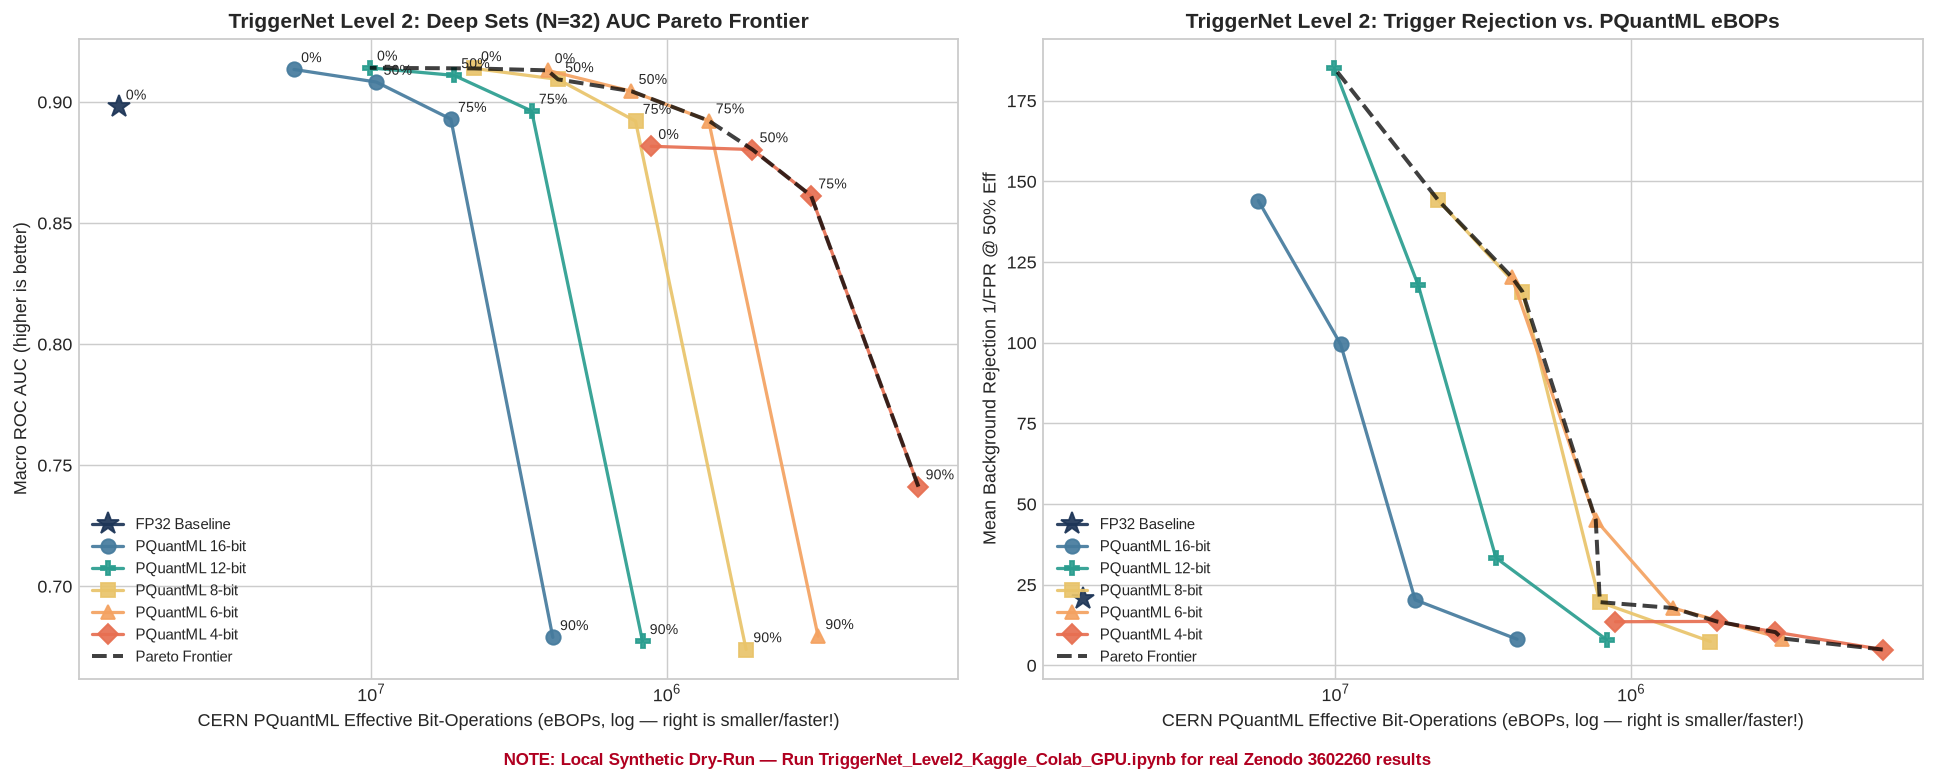

In [3]:
def find_pareto_frontier(points_df: pd.DataFrame, x_col: str, y_col: str) -> pd.DataFrame:
    """Return non-dominated points minimizing x_col (eBOPs) and maximizing y_col (AUC/rejection)."""
    ordered = points_df.sort_values(x_col, ascending=True)
    frontier = []
    best_y = -float("inf")
    for _, row in ordered.iterrows():
        if row[y_col] > best_y:
            frontier.append(row)
            best_y = row[y_col]
    return pd.DataFrame(frontier)


plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

palette = {32: "#1d3557", 16: "#457b9d", 12: "#2a9d8f", 8: "#e9c46a", 6: "#f4a261", 4: "#e76f51"}
markers = {32: "*", 16: "o", 12: "P", 8: "s", 6: "^", 4: "D"}

for bits in [32, 16, 12, 8, 6, 4]:
    sub = df[df["total_bits"] == bits].sort_values("pquant_ebops", ascending=False)
    lbl = "FP32 Baseline" if bits == 32 else f"PQuantML {bits}-bit"
    ms = 13 if bits == 32 else 8
    axes[0].plot(sub["pquant_ebops"], sub["macro_auc"], marker=markers[bits], color=palette[bits],
                 linewidth=1.8, markersize=ms, label=lbl, alpha=0.92)
    axes[1].plot(sub["pquant_ebops"], sub["mean_rej_50"], marker=markers[bits], color=palette[bits],
                 linewidth=1.8, markersize=ms, label=lbl, alpha=0.92)
    for _, r in sub.iterrows():
        sp_tag = f"{int(round(r['target_sparsity']*100))}%"
        axes[0].annotate(sp_tag, (r["pquant_ebops"], r["macro_auc"]), textcoords="offset points", xytext=(4, 4), fontsize=7.5)

# Overlay global Pareto envelope
pareto_auc = find_pareto_frontier(df, "pquant_ebops", "macro_auc")
pareto_rej = find_pareto_frontier(df, "pquant_ebops", "mean_rej_50")
axes[0].plot(pareto_auc["pquant_ebops"], pareto_auc["macro_auc"], "k--", linewidth=2.2, alpha=0.75, label="Pareto Frontier")
axes[1].plot(pareto_rej["pquant_ebops"], pareto_rej["mean_rej_50"], "k--", linewidth=2.2, alpha=0.75, label="Pareto Frontier")

for ax, ylabel, title in [
    (axes[0], "Macro ROC AUC (higher is better)", f"TriggerNet Level 2: Deep Sets (N={N_CONSTITUENTS}) AUC Pareto Frontier"),
    (axes[1], "Mean Background Rejection 1/FPR @ 50% Eff", f"TriggerNet Level 2: Trigger Rejection vs. PQuantML eBOPs"),
]:
    ax.set_xscale("log")
    ax.invert_xaxis()
    ax.set_xlabel("CERN PQuantML Effective Bit-Operations (eBOPs, log — right is smaller/faster!)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold", fontsize=11.5)
    ax.legend(fontsize=8.5, loc="lower left")

if DATA_MODE != "REAL_ZENODO_3602260":
    fig.text(0.5, 0.01, "NOTE: Local Synthetic Dry-Run — Run TriggerNet_Level2_Kaggle_Colab_GPU.ipynb for real Zenodo 3602260 results",
             ha="center", color="#b00020", fontweight="bold", fontsize=9.5)

plt.tight_layout(rect=[0, 0.03, 1, 1])
out_fig = FIG_DIR / "06_level2_hero_pareto.png"
plt.savefig(out_fig, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved Hero Pareto Frontier to {out_fig}")
print("\nGlobal Pareto-Optimal Operating Points (AUC):")
print(pareto_auc[["tag", "total_bits", "actual_sparsity", "pquant_ebops", "ebops_reduction_pct", "accuracy", "macro_auc"]].to_string(index=False))